In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
# sys.path.append('../')
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path

sys.path.append('/global/cfs/cdirs/alice/heppy_soft/05-11-2023/yasp/software/root/6.28.00/lib')
import ROOT

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black', 'gold', 'hotpink']
# L_colors = ['hotpink', 'red', 'darkorange', 'gold', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P', "X", "*", "o", '8']
# L_markers = ['s', 'p', '^', 'v', 'd', 'P', "X", "*", '8']

Welcome to JupyROOT 6.28/06


In [3]:
# closure test? i.e. there is truth pythia data somewhere to compare to
closure = True

JETPT_BINS = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500], dtype=np.float64)

RL_NBINS = 25
RL_MIN, RL_MAX = 0.01, 1.0
RL_BINS = np.logspace(np.log10(RL_MIN), np.log10(RL_MAX), RL_NBINS + 1)

W_NBINS = 20 #30 #100
W_MIN, W_MAX = 0.0, 0.3 #1.0 #0.3
W_BINS = np.logspace(-5,-0.5,W_NBINS+1)


# define binnings
n_bins_true = [9, 25, 20] # jet pt, RL, weight #[20, 12, 6] # [20, 22, 7]
# RL_bins = np.array([0.00796, 0.01, 0.0144544, 0.020893, 0.0301995, 0.0436516,
#                     0.0630957, 0.0912011, 0.131826, 0.190546, 0.275423, 0.398107, 0.47863])
# # RL_bins = np.logspace(-2, 0, n_bins_true[1]+1)
RL_bins = RL_BINS

# binning = [np.logspace(-5,-0.5,n_bins_true[0]+1), \
#             RL_bins, \
#             # np.logspace(-2.299,0,n_bins_true[1]+1), \ 
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
#             # np.array([5, 10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning = [JETPT_BINS, \
           RL_bins, \
           W_BINS ]
print(binning)
# bincenters = [ get_log_bincenters(binning[0]), get_log_bincenters(binning[1]), get_lin_bincenters(binning[2]) ]
bincenters = [ get_lin_bincenters(binning[0]), get_log_bincenters(binning[1]), get_log_bincenters(binning[2]) ]
binwidths = [ np.array(get_binwidths(a)) for a in binning ]
print(binwidths)

n_bins = [9, 25, 20] #[20, 12, 6] # [20, 22, 6] # WARNING RooUnfold seg faults if too many bins used
# binning_reco = [np.logspace(-5,-0.5,n_bins[0]+1), \
#             RL_bins, \
#             # np.logspace(-2.299,0,n_bins[1]+1), \
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning_reco = [JETPT_BINS, \
                RL_bins, \
                W_BINS ]
# bincenters_reco = [ get_log_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_lin_bincenters(binning_reco[2]) ]
bincenters_reco = [ get_lin_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_log_bincenters(binning_reco[2]) ]
binwidths_reco = [ np.array(get_binwidths(a)) for a in binning_reco ]

labels = ["jet $p_T$", "$R_L$", "energy weight"] #["energy weight", "$R_L$", ""]

n_iter = 5

[array([ 10.,  20.,  40.,  60.,  80., 100., 120., 150., 200., 500.]), array([0.01      , 0.01202264, 0.0144544 , 0.01737801, 0.02089296,
       0.02511886, 0.03019952, 0.03630781, 0.04365158, 0.05248075,
       0.06309573, 0.07585776, 0.09120108, 0.10964782, 0.13182567,
       0.15848932, 0.19054607, 0.22908677, 0.27542287, 0.33113112,
       0.39810717, 0.47863009, 0.57543994, 0.69183097, 0.83176377,
       1.        ]), array([1.00000000e-05, 1.67880402e-05, 2.81838293e-05, 4.73151259e-05,
       7.94328235e-05, 1.33352143e-04, 2.23872114e-04, 3.75837404e-04,
       6.30957344e-04, 1.05925373e-03, 1.77827941e-03, 2.98538262e-03,
       5.01187234e-03, 8.41395142e-03, 1.41253754e-02, 2.37137371e-02,
       3.98107171e-02, 6.68343918e-02, 1.12201845e-01, 1.88364909e-01,
       3.16227766e-01])]
[array([ 10.,  20.,  20.,  20.,  20.,  20.,  30.,  50., 300.]), array([0.00202264, 0.00243175, 0.00292361, 0.00351495, 0.0042259 ,
       0.00508065, 0.00610829, 0.00734378, 0.00882916, 0.010614

In [4]:
# file defs, hist imports

f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/response_groomed_forunfolding_merged.root")
# f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/58416144/AnalysisResultsMerged_groomedbins.root")
f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/60017705/AnalysisResultsMerged_groomedbins.root")
f_unfolded1D = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded.root")

f_refolded1D =ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D_tests.root")


# TESTING!!!

In [5]:
lab="AA"

# Data, reco - from original preunfold data file
h3_raw = f_preunfold_data["{}_sd0.1_raw".format(lab)]
h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"]

# MC, reco, matched - from preunfold RM file
h3_reco_matched = f_preunfold_rm["groomed_{}_reco".format(lab)]
h1_reco_matched = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #reco1D"]

# MC, true, matched - from preunfold RM file
h3_gen_matched = f_preunfold_rm["groomed_{}_gen".format(lab)]
h1_gen_matched = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #gen1D"]

# MC, reco, ALL - from preunfold RM file
h3_reco_all = f_preunfold_rm["groomed_{}_reco_unmatched".format(lab)]
h1_reco_all = f_preunfold_rm["jet_all_rec_pur_den_groomed"] #reco1D"]

# MC, true, ALL - from preunfold RM file
h3_gen_all = f_preunfold_rm["groomed_{}_gen_unmatched".format(lab)]
h1_gen_all = f_preunfold_rm["jet_all_gen_eff_den_groomed"] #gen1D"]

# Data, true - from unfolded file
h3_unfolded = []
h1_unfolded = [] 
for i in range(1,n_iter+1):
    h3_unfolded.append(f_unfolded["Bayesian_Unfolded_{}_iter{}".format(lab, i)])
    h1_unfolded.append(f_unfolded1D["Baysian_Unfolded1Diter{}".format(i)])

# purity/eff from unfolding file
h1_purity = f_unfolded1D["purity"]
h1_efficiency = f_unfolded1D["efficiency"]

# what is this? !!!!! !!!!!! !!!!! !!!!!!
h3_raw_purity = f_unfolded["{}_raw_corrected".format(lab)] #"raw{}".format(bkg)] # TODO: is this right??




In [6]:
## HISTOGRAMS TO CHECK:

# Check cuts on h3_raw with these histograms
h_raw_data_in_ptbins = []
for i in range(1,8):
    print(int(JETPT_BINS[i]), int(JETPT_BINS[i+1]))
    h_raw_data_in_ptbins.append(f_preunfold_data["hist_{}_gjetpt{}_{}_sd0.1_wwradpt".format( lab, int(JETPT_BINS[i]), int(JETPT_BINS[i+1]) )])

# Compare 1D jet pt spectra from unfolded file to raw data file
h1_raw_unfoldedfile = f_unfolded1D["groomed_sd0.1_jet_pt_raw1D"]

# Compare 1D jet pt gen from unfolded file with original MC (preunfold RM file)
h1_gen_unfoldedfile = []
for i in range(1, n_iter+1):
    h1_gen_unfoldedfile.append(f_unfolded1D["h1jetpt_gen_groomed;{}".format(i)]) # 9 rewrites of this
# h1_gen_unfoldedfile_test = f_unfolded1D["h1jetpt_gen_groomed;5"]

# Compare this with 3D gen?? from unfolded file with original MC file
h3_gen_unfoldedfile = f_unfolded["groomed_{}_gen".format(lab)] # 5 rewrites of this

# Compare the refolding plots this with the 1D jet pt spectra
h1_raw_refolding = f_refolded1D["h1_raw"]
h1_purity_refolding = f_refolded1D["purity"]
h1_efficiency_refolding = f_refolded1D["efficiency"]
h1_unfolded_refolding = [] 
for i in range(1,n_iter+1):
    h1_unfolded_refolding.append(f_unfolded1D["Baysian_Unfolded1Diter{}".format(i)])




20 40
40 60
60 80
80 100
100 120
120 150
150 200


In [7]:
proj = lambda a : a.values()

# Extract 1D array values
y1_purity = proj(h1_purity)
y1_efficiency = proj(h1_efficiency)

y1_raw = proj(h1_raw)
y1_raw_unfolded = proj(h1_raw_unfoldedfile)
y1_raw_unfolded_unpurity = y1_raw_unfolded / y1_purity

y1_unfolded = [proj(a) for a in h1_unfolded]
y1_unfolded_unefficiency = y1_unfolded * y1_efficiency

y1_raw_refolding = proj(h1_raw_refolding)
y1_purity_refolding = proj(h1_purity_refolding)
y1_efficiency_refolding = proj(h1_efficiency_refolding)
y1_unfolded_refolding = [proj(a) for a in h1_unfolded_refolding]


y1_gen_matched = proj(h1_gen_matched)
y1_gen_all = proj(h1_gen_all)
y1_gen_unfolded = [proj(a) for a in h1_gen_unfoldedfile]

y1_reco_matched = proj(h1_reco_matched)
y1_reco_all = proj(h1_reco_all)


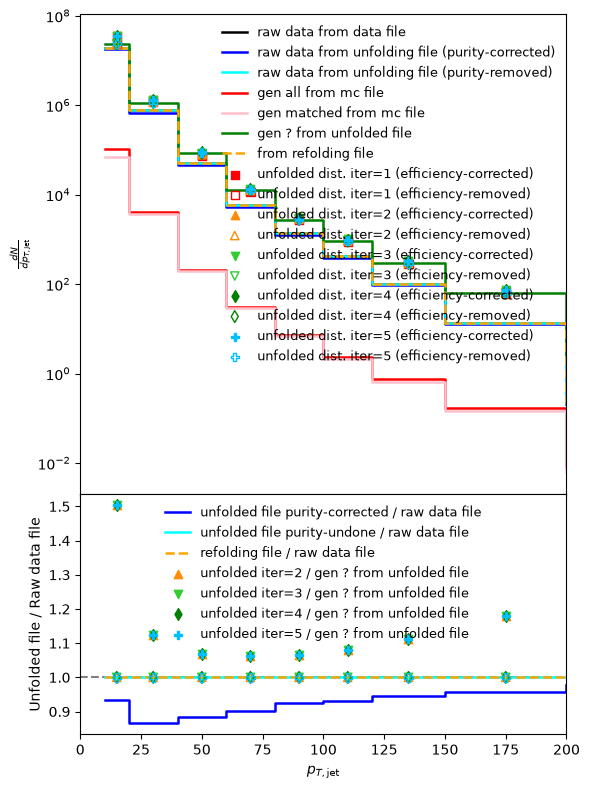

In [8]:
# COMPARISON OF RAW DATA FROM INPUT DATA FILE (black) AND UNFOLDED FILE (blue)
# COMPARISON OF MC GEN FROM INPUT RM FILE (red=all, pink=matched) AND UNFOLDED FILE (green)

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

ax.step(binning[0][:-1], y1_raw / binwidths[0], where="post", color='black', lw=1.8, ls='-',
            label="raw data from data file", zorder=3)
ax.step(binning[0][:-1], y1_raw_unfolded / binwidths[0], where="post", color='blue', lw=1.8, ls='-',
            label="raw data from unfolding file (purity-corrected)", zorder=3)
ax.step(binning[0][:-1], y1_raw_unfolded_unpurity / binwidths[0], where="post", color='cyan', lw=1.8, ls='-',
            label="raw data from unfolding file (purity-removed)", zorder=3)
ax.step(binning[0][:-1], y1_gen_all / binwidths[0], where="post", color='red', lw=1.8, ls='-',
            label="gen all from mc file", zorder=3)
ax.step(binning[0][:-1], y1_gen_matched / binwidths[0], where="post", color='pink', lw=1.8, ls='-',
            label="gen matched from mc file", zorder=3)
ax.step(binning[0][:-1], y1_gen_unfolded[4] / binwidths[0], where="post", color='green', lw=1.8, ls='-',
            label="gen ? from unfolded file", zorder=3) # purity corrected, efficiency not corrected # HERE, SELECTING THE 5th ITERATION WITH [4]
ax.step(binning[0][:-1], y1_raw_refolding / binwidths[0], where="post", color='orange', lw=1.8, ls='--',
            label="from refolding file", zorder=3)

for i in range(n_iter):
    ax.scatter(bincenters[0], y1_unfolded[i] / binwidths[0], color=L_colors[i], marker=L_markers[i],
            label="unfolded dist. iter={} (efficiency-corrected)".format(i+1), zorder=3) # purity AND efficiency corrected
    ax.scatter(bincenters[0], y1_unfolded_unefficiency[i] / binwidths[0], color=L_colors[i], marker=L_markers[i], facecolors='none',
                label="unfolded dist. iter={} (efficiency-removed)".format(i+1), zorder=3) # purity AND efficiency corrected, but then efficiency correction undone
    

ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)

yvals_ratio = safe_divide(y1_raw_unfolded, y1_raw, filler=1)
yvals_ratio2 = safe_divide(y1_raw_unfolded_unpurity, y1_raw, filler=1)
yvals_ratio3 = safe_divide(y1_raw_refolding, y1_raw, filler=1)

ax.step(binning[0][:-1], yvals_ratio, where="post", color='blue', lw=1.8, ls='-',
            zorder=2, label=f"unfolded file purity-corrected / raw data file")
ax.step(binning[0][:-1], yvals_ratio2, where="post", color='cyan', lw=1.8, ls='-',
            zorder=2, label=f"unfolded file purity-undone / raw data file")
ax.step(binning[0][:-1], yvals_ratio3, where="post", color='orange', lw=1.8, ls='--',
            zorder=2, label=f"refolding file / raw data file")


for i in range(n_iter):
    if i < 1:
        continue
    yvals_ratio = safe_divide(y1_unfolded[i], y1_gen_unfolded[i], filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=L_markers[i],
            label="unfolded iter={} / gen ? from unfolded file".format(i+1), zorder=3)
    
    yvals_ratio = safe_divide(y1_unfolded_unefficiency[i], y1_gen_unfolded[i], filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=L_markers[i], facecolors='none', zorder=3) #label="unfolded iter={} / gen ? from unfolded file".format(i+1), 

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
ax.set_ylabel("Unfolded file / Raw data file")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()

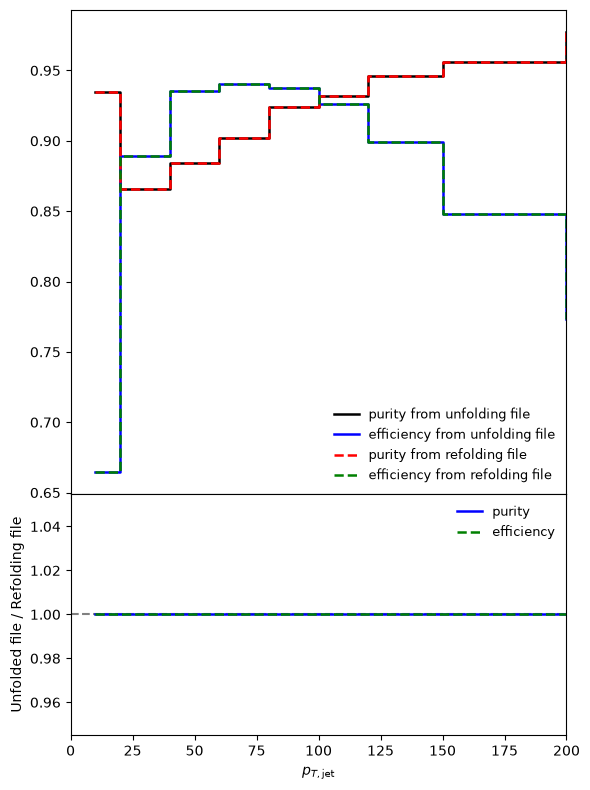

In [9]:
# COMPARISON OF PURITY/EFFICIENCY FROM UNFOLDING FILE (-) AND REFOLDING FILE (--)

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

ax.step(binning[0][:-1], y1_purity, where="post", color='black', lw=1.8, ls='-',
            label="purity from unfolding file", zorder=3)
ax.step(binning[0][:-1], y1_efficiency, where="post", color='blue', lw=1.8, ls='-',
            label="efficiency from unfolding file", zorder=3)
ax.step(binning[0][:-1], y1_purity_refolding, where="post", color='red', lw=1.8, ls='--',
            label="purity from refolding file", zorder=3)
ax.step(binning[0][:-1], y1_efficiency_refolding, where="post", color='green', lw=1.8, ls='--',
            label="efficiency from refolding file", zorder=3)


ax.set_xlim(pt_lims)
# ax.set_yscale("log")
# ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)

yvals_ratio = safe_divide(y1_purity_refolding, y1_purity, filler=1)
yvals_ratio2 = safe_divide(y1_efficiency_refolding, y1_efficiency, filler=1)

ax.step(binning[0][:-1], yvals_ratio, where="post", color='blue', lw=1.8, ls='-',
            zorder=2, label=f"purity")
ax.step(binning[0][:-1], yvals_ratio2, where="post", color='green', lw=1.8, ls='--',
            zorder=2, label=f"efficiency")

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
ax.set_ylabel("Unfolded file / Refolding file")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()

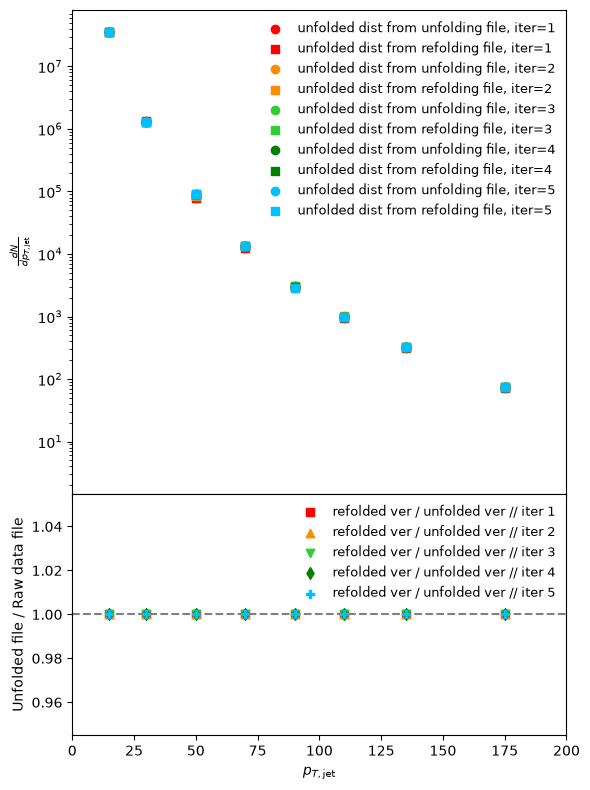

In [10]:
# COMPARISON OF UNFOLDED DISTRIBUTIONS FROM UNFOLDING FILE (-) AND REFOLDING FILE (--)

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

for i in range(n_iter):
    ax.scatter(bincenters[0], y1_unfolded[i] / binwidths[0], color=L_colors[i], marker='o',
            label="unfolded dist from unfolding file, iter={}".format(i+1), zorder=3) # purity AND efficiency corrected
    # ax.scatter(bincenters[0], y1_unfolded_unefficiency[i] / binwidths[0], color=L_colors[i], marker='o', facecolors='none',
    #             label="unfolded dist. iter={} (efficiency-removed)".format(i+1), zorder=3) # purity AND efficiency corrected, but then efficiency correction undone
    ax.scatter(bincenters[0], y1_unfolded_refolding[i] / binwidths[0], color=L_colors[i], marker='s',
                label="unfolded dist from refolding file, iter={}".format(i+1), zorder=3) # purity AND efficiency corrected
    
    

ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)


for i in range(n_iter):
    yvals_ratio = safe_divide(y1_unfolded_refolding[i], y1_unfolded[i], filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=L_markers[i], zorder=3, label="refolded ver / unfolded ver // iter {}".format(i+1))

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
ax.set_ylabel("Unfolded file / Raw data file")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()

# Comparing the input distributions to response matrix

In [11]:
# compare y1_gen_matched and y1_reco_matched with the projections of the response matrix
h_matrix1D = f_unfolded1D["matrix1D"]
# h_matrix1D = f_refolded1D["matrix1D"]
matrix_vals = h_matrix1D.values()

y1_proj_matrix1D_reco = matrix_vals.sum(axis=1)
y1_proj_matrix1D_gen = matrix_vals.sum(axis=0) #proj(h1_proj_matrix1D_gen)

# ======================================================

# Check with the root response matrix (instead of roounfold one)
f_preunfold_rm2 = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/response_groomed_merged_partial.root")
# f_preunfold_rm2 = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/0/559348/1/response.root")

h_matrix1D_B = f_preunfold_rm2["resp_jetpt_groomed"]
matrix_vals_B = h_matrix1D_B.values()

y1_proj_matrix1D_reco_B = matrix_vals_B.sum(axis=1)
y1_proj_matrix1D_gen_B = matrix_vals_B.sum(axis=0) 

h1_gen_matched_B = f_preunfold_rm2["jet_match_gen_eff_num_groomed"]
h1_gen_all_B = f_preunfold_rm2["jet_all_gen_eff_den_groomed"]
h1_rec_matched_B = f_preunfold_rm2["jet_match_rec_pur_num_groomed"]
h1_rec_all_B = f_preunfold_rm2["jet_all_rec_pur_den_groomed"]

y1_gen_matched_B = proj(h1_gen_matched_B)
y1_gen_all_B = proj(h1_gen_all_B)
y1_rec_matched_B = proj(h1_rec_matched_B)
y1_rec_all_B = proj(h1_rec_all_B)

In [12]:
total_entries = h_matrix1D.member("fEntries")
print("total entries in matrix:", total_entries)

h1_gen_matched_entries = h1_gen_matched.member("fEntries")
h1_rec_matched_entries = h1_reco_matched.member("fEntries")
h1_gen_all_entries = h1_gen_all.member("fEntries")
h1_rec_all_entries = h1_reco_all.member("fEntries")

print("entries in matched gen:", h1_gen_matched_entries)
print("entries in matched reco:", h1_rec_matched_entries)
print("entries in all gen:", h1_gen_all_entries)
print("entries in all reco:", h1_rec_all_entries)


### Study # of overflow/underflow

# Project the 2D boost histogram with flow enabled
# Axis 0 = X projection (reconstructed), Axis 1 = Y projection (generated)
h1_reco_proj = h_matrix1D.to_boost().project(0)
h1_gen_proj = h_matrix1D.to_boost().project(1)

# Extract values including underflow and overflow
reco_vals = h1_reco_proj.values(flow=True)
gen_vals = h1_gen_proj.values(flow=True)
print("reco projection per bin", reco_vals)
print("gen projection per bin", gen_vals)

# For a 1D Histogram (or projection):
# Returns an array of size (nbins + 2):
# Index 0 = underflow, Indices 1 to nbins = normal bins, Index nbins + 1 = overflow
vals_with_flow_gen_matched = h1_gen_matched.values(flow=True)
vals_with_flow_rec_matched = h1_reco_matched.values(flow=True)
vals_with_flow_gen_all = h1_gen_all.values(flow=True)
vals_with_flow_rec_all = h1_reco_all.values(flow=True)
# underflow_1d_gen_matched = vals_with_flow_gen_matched[0]
# overflow_1d_gen_matched = vals_with_flow_gen_matched[-1]
print("gen matched per bin", vals_with_flow_gen_matched)
print("rec matched per bin", vals_with_flow_rec_matched)
print("gen all per bin", vals_with_flow_gen_all)
print("rec all per bin", vals_with_flow_gen_all)



total entries in matrix: 112001881.0
entries in matched gen: 112001881.0
entries in matched reco: 112001881.0
entries in all gen: 140785380.0
entries in all reco: 115727648.0


reco projection per bin [7.53197650e+05 5.57195604e+05 4.16105626e+04 2.00059865e+03
 2.77852631e+02 6.12406949e+01 1.76404427e+01 6.52408235e+00
 1.53465726e+00 1.54922685e-01 7.77150717e-08]
gen projection per bin [5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03
 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01
 7.20093827e+00 1.85381064e+00 1.08949337e-03]
gen matched per bin [5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03
 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01
 7.20093827e+00 1.85381064e+00 1.08949337e-03]
rec matched per bin [7.53197650e+05 5.57195604e+05 4.16105626e+04 2.00059865e+03
 2.77852631e+02 6.12406949e+01 1.76404427e+01 6.52408235e+00
 1.53465726e+00 1.54922685e-01 7.77150717e-08]
gen all per bin [1.47715355e+06 1.05761909e+06 8.10967326e+04 4.13869642e+03
 6.12678956e+02 1.46943608e+02 4.65407242e+01 2.21718644e+01
 8.49004960e+00 2.39757851e+00 1.66688664e-03]
rec all per bin [1.47715355e+06 1.05761909e+06 8.109

In [13]:
total_entries = h_matrix1D_B.member("fEntries")
print("total entries in matrix:", total_entries)

h1_gen_matched_B_entries = h1_gen_matched_B.member("fEntries")
h1_rec_matched_B_entries = h1_rec_matched_B.member("fEntries")
h1_gen_all_B_entries = h1_gen_all_B.member("fEntries")
h1_rec_all_B_entries = h1_rec_all_B.member("fEntries")

print("entries in matched gen:", h1_gen_matched_B_entries)
print("entries in matched reco:", h1_rec_matched_B_entries)
print("entries in all gen:", h1_gen_all_B_entries)
print("entries in all reco:", h1_rec_all_B_entries)


### Study # of overflow/underflow

# Project the 2D boost histogram with flow enabled
# Axis 0 = X projection (reconstructed), Axis 1 = Y projection (generated)
h1_reco_proj = h_matrix1D_B.to_boost().project(0)
h1_gen_proj = h_matrix1D_B.to_boost().project(1)

# Extract values including underflow and overflow
reco_vals = h1_reco_proj.values(flow=True)
gen_vals = h1_gen_proj.values(flow=True)
print("reco projection per bin", reco_vals)
print("gen projection per bin", gen_vals)

# For a 1D Histogram (or projection):
# Returns an array of size (nbins + 2):
# Index 0 = underflow, Indices 1 to nbins = normal bins, Index nbins + 1 = overflow
vals_with_flow_gen_matched_B = h1_gen_matched_B.values(flow=True)
vals_with_flow_rec_matched_B = h1_rec_matched_B.values(flow=True)
vals_with_flow_gen_all_B = h1_gen_all_B.values(flow=True)
vals_with_flow_rec_all_B = h1_rec_all_B.values(flow=True)
# underflow_1d_gen_matched_B = vals_with_flow_gen_matched_B[0]
# overflow_1d_gen_matched_B = vals_with_flow_gen_matched_B[-1]
print("gen matched per bin", vals_with_flow_gen_matched_B)
print("rec matched per bin", vals_with_flow_rec_matched_B)
print("gen all per bin", vals_with_flow_gen_all_B)
print("rec all per bin", vals_with_flow_gen_all_B)



total entries in matrix: 112001881.0
entries in matched gen: 112001881.0
entries in matched reco: 112001881.0
entries in all gen: 140785380.0
entries in all reco: 115727648.0
reco projection per bin [7.53197650e+05 5.57195604e+05 4.16105626e+04 2.00059865e+03
 2.77852631e+02 6.12406949e+01 1.76404427e+01 6.52408235e+00
 1.53465726e+00 1.54922685e-01 7.77150717e-08]
gen projection per bin [5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03
 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01
 7.20093827e+00 1.85381064e+00 1.08949337e-03]
gen matched per bin [5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03
 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01
 7.20093827e+00 1.85381064e+00 1.08949337e-03]
rec matched per bin [7.53197650e+05 5.57195604e+05 4.16105626e+04 2.00059865e+03
 2.77852631e+02 6.12406949e+01 1.76404427e+01 6.52408235e+00
 1.53465726e+00 1.54922685e-01 7.77150717e-08]
gen all per bin [1.47715355e+06 1.05761909e+06 8.10967326e+04 

In [ ]:
gen projection per bin:
5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00 1.85381064e+00 1.08949337e-03]
gen matched per bin:
5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00 1.85381064e+00 1.08949337e-03]
gen projection per bin 
5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00 1.85381064e+00 1.08949337e-03]
gen matched per bin 
5.74307350e+05 7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00 1.85381064e+00 1.08949337e-03]





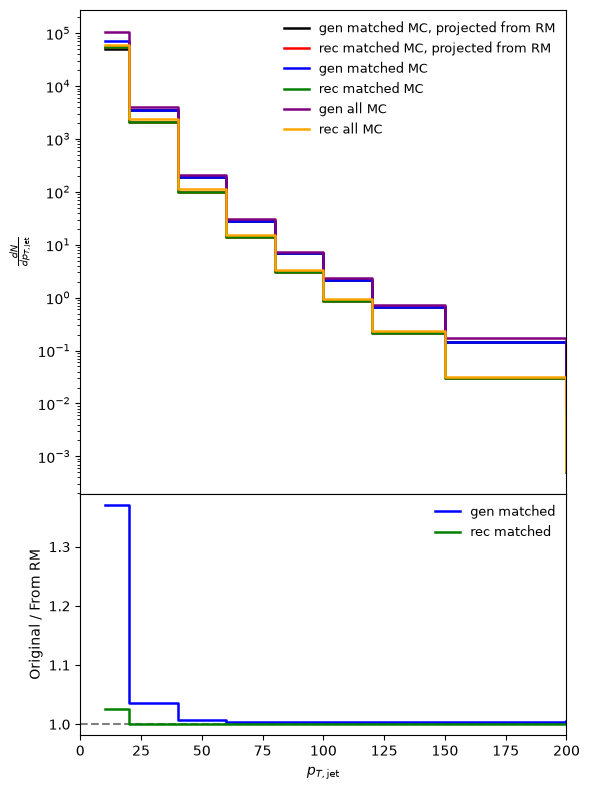

In [15]:
# COMPARISON OF RESPONSE MATRIX WITH 1D OUTPUT

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

ax.step(binning[0][:-1], y1_proj_matrix1D_gen / binwidths[0], where="post", color='black', lw=1.8, ls='-',
            label="gen matched MC, projected from RM", zorder=3)
ax.step(binning[0][:-1], y1_proj_matrix1D_reco / binwidths[0], where="post", color='red', lw=1.8, ls='-',
            label="rec matched MC, projected from RM", zorder=3)

ax.step(binning[0][:-1], y1_gen_matched / binwidths[0], where="post", color='blue', lw=1.8, ls='-',
            label="gen matched MC", zorder=3)
ax.step(binning[0][:-1], y1_reco_matched / binwidths[0], where="post", color='green', lw=1.8, ls='-',
            label="rec matched MC", zorder=3)

ax.step(binning[0][:-1], y1_gen_all / binwidths[0], where="post", color='purple', lw=1.8, ls='-',
            label="gen all MC", zorder=3)
ax.step(binning[0][:-1], y1_reco_all / binwidths[0], where="post", color='orange', lw=1.8, ls='-',
            label="rec all MC", zorder=3)




ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)


yvals_ratio = safe_divide(y1_gen_matched, y1_proj_matrix1D_gen, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='blue', lw=1.8, ls='-', label="gen matched", zorder=3)

yvals_ratio = safe_divide(y1_reco_matched, y1_proj_matrix1D_reco, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='green', lw=1.8, ls='-', label="rec matched", zorder=3)


# yvals_ratio = safe_divide(y1_gen_all, y1_proj_matrix1D_gen, filler=1)
# ax.step(binning[0][:-1], yvals_ratio, where="post", color='purple', lw=1.8, ls='-', label="gen all", zorder=3)

# yvals_ratio = safe_divide(y1_reco_all, y1_proj_matrix1D_reco, filler=1)
# ax.step(binning[0][:-1], yvals_ratio, where="post", color='orange', lw=1.8, ls='-', label="rec all", zorder=3)


ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
# ax.set_ylim(0, 6.0)
ax.set_ylabel("Original / From RM")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()

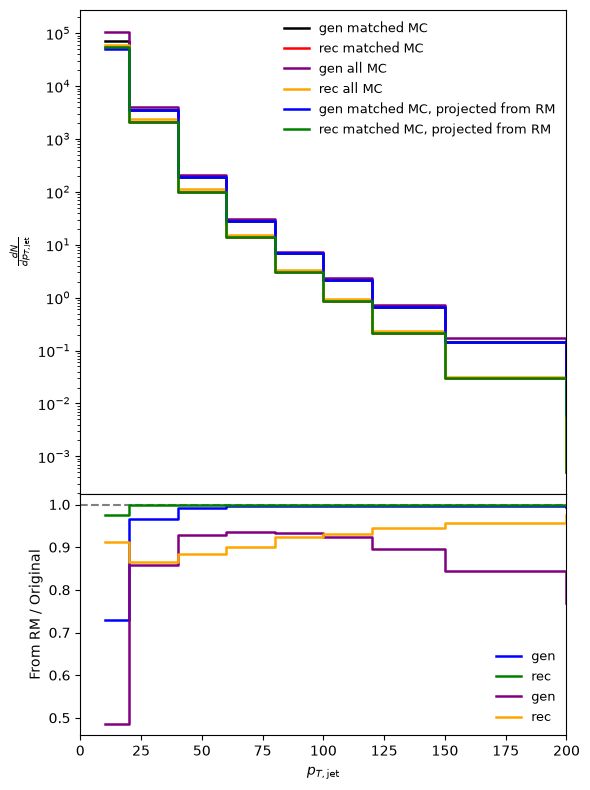

In [31]:
# COMPARISON OF RESPONSE MATRIX (ROOT HIST) WITH 1D OUTPUT

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

ax.step(binning[0][:-1], y1_gen_matched_B / binwidths[0], where="post", color='black', lw=1.8, ls='-',
            label="gen matched MC", zorder=3)
ax.step(binning[0][:-1], y1_rec_matched_B / binwidths[0], where="post", color='red', lw=1.8, ls='-',
            label="rec matched MC", zorder=3)

ax.step(binning[0][:-1], y1_gen_all_B / binwidths[0], where="post", color='purple', lw=1.8, ls='-',
            label="gen all MC", zorder=3)
ax.step(binning[0][:-1], y1_rec_all_B / binwidths[0], where="post", color='orange', lw=1.8, ls='-',
            label="rec all MC", zorder=3)

ax.step(binning[0][:-1], y1_proj_matrix1D_gen_B / binwidths[0], where="post", color='blue', lw=1.8, ls='-',
            label="gen matched MC, projected from RM", zorder=3)
ax.step(binning[0][:-1], y1_proj_matrix1D_reco_B / binwidths[0], where="post", color='green', lw=1.8, ls='-',
            label="rec matched MC, projected from RM", zorder=3)


ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)


yvals_ratio = safe_divide(y1_proj_matrix1D_gen_B, y1_gen_matched_B, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='blue', lw=1.8, ls='-', label="gen", zorder=3)

yvals_ratio = safe_divide(y1_proj_matrix1D_reco_B, y1_rec_matched_B, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='green', lw=1.8, ls='-', label="rec", zorder=3)


yvals_ratio = safe_divide(y1_proj_matrix1D_gen_B, y1_gen_all_B, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='purple', lw=1.8, ls='-', label="gen", zorder=3)

yvals_ratio = safe_divide(y1_proj_matrix1D_reco_B, y1_rec_all_B, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='orange', lw=1.8, ls='-', label="rec", zorder=3)


ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
# ax.set_ylim(0, 6.0)
ax.set_ylabel("From RM / Original")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()


# TRIVIAL CLOSURE TESTING

In [11]:
# Trivial closure test
# These are both eff and purity turned on
h1_trivial_unfolded_all = []
h1_trivial_refolded_all = []
h1_trivial_unfolded_matched = []
h1_trivial_refolded_matched = []
for i in range(1, n_iter+1):
    h1_trivial_unfolded_all.append( f_refolded1D["trivial_closure/Trivial_Baysian_All_Unfolded1Diter{}".format(i)] )
    h1_trivial_refolded_all.append( f_refolded1D["trivial_closure/Trivial_Baysian_All_Refolded1Diter{}".format(i)] )
    h1_trivial_unfolded_matched.append( f_refolded1D["trivial_closure/Trivial_Baysian_Matched_Unfolded1Diter{}".format(i)] )
    h1_trivial_refolded_matched.append( f_refolded1D["trivial_closure/Trivial_Baysian_Matched_Refolded1Diter{}".format(i)] )

h1_rec_matched_in = f_refolded1D["trivial_closure/rec_work_Matched"]
h1_rec_all_in = f_refolded1D["trivial_closure/rec_work_All"]

In [12]:
proj = lambda a : a.values()

y1_trivial_unfolded_all = [proj(a) for a in h1_trivial_unfolded_all]
y1_trivial_refolded_all = [proj(a) for a in h1_trivial_refolded_all]
y1_trivial_unfolded_matched = [proj(a) for a in h1_trivial_unfolded_matched]
y1_trivial_refolded_matched = [proj(a) for a in h1_trivial_refolded_matched]

y1_reco_all = proj(h1_reco_all)
y1_gen_all = proj(h1_gen_all)
y1_reco_matched = proj(h1_reco_matched)
y1_gen_matched = proj(h1_gen_matched)

y1_trivial_unfolded_all_unefficiency = y1_trivial_unfolded_all * y1_efficiency
y1_trivial_unfolded_all_unpurity = y1_trivial_unfolded_all * y1_purity

y1_rec_matched_in = proj(h1_rec_matched_in)
y1_rec_all_in = proj(h1_rec_all_in)
y1_rec_all_in_nopurity = y1_rec_all_in / y1_purity

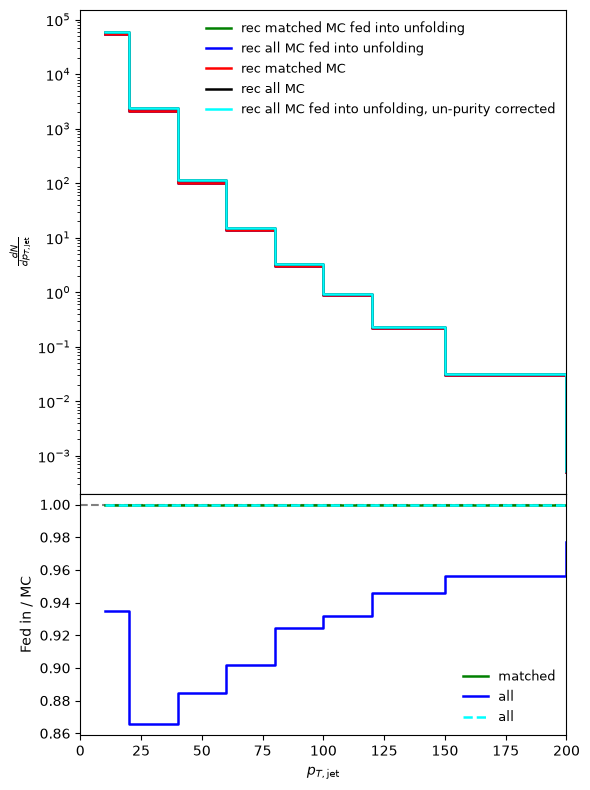

In [13]:
# COMPARISON OF UNFOLDED DISTRIBUTIONS FROM UNFOLDING FILE (-) AND REFOLDING FILE (--)

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

ax.step(binning[0][:-1], y1_rec_matched_in / binwidths[0], where="post", color='green', lw=1.8, ls='-',
            label="rec matched MC fed into unfolding", zorder=3)
ax.step(binning[0][:-1], y1_rec_all_in / binwidths[0], where="post", color='blue', lw=1.8, ls='-',
            label="rec all MC fed into unfolding", zorder=3)
ax.step(binning[0][:-1], y1_reco_matched / binwidths[0], where="post", color='red', lw=1.8, ls='-',
            label="rec matched MC", zorder=3)
ax.step(binning[0][:-1], y1_reco_all / binwidths[0], where="post", color='black', lw=1.8, ls='-',
            label="rec all MC", zorder=3)
ax.step(binning[0][:-1], y1_rec_all_in_nopurity / binwidths[0], where="post", color='cyan', lw=1.8, ls='-',
            label="rec all MC fed into unfolding, un-purity corrected", zorder=3)


ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)


yvals_ratio = safe_divide(y1_rec_matched_in, y1_reco_matched, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='green', lw=1.8, ls='-', label="matched", zorder=3)

yvals_ratio = safe_divide(y1_rec_all_in, y1_reco_all, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='blue', lw=1.8, ls='-', label="all", zorder=3)

yvals_ratio = safe_divide(y1_rec_all_in_nopurity, y1_reco_all, filler=1)
ax.step(binning[0][:-1], yvals_ratio, where="post", color='cyan', lw=1.8, ls='--', label="all", zorder=3)

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
# ax.set_ylim(0, 5.0)
ax.set_ylabel("Fed in / MC")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()

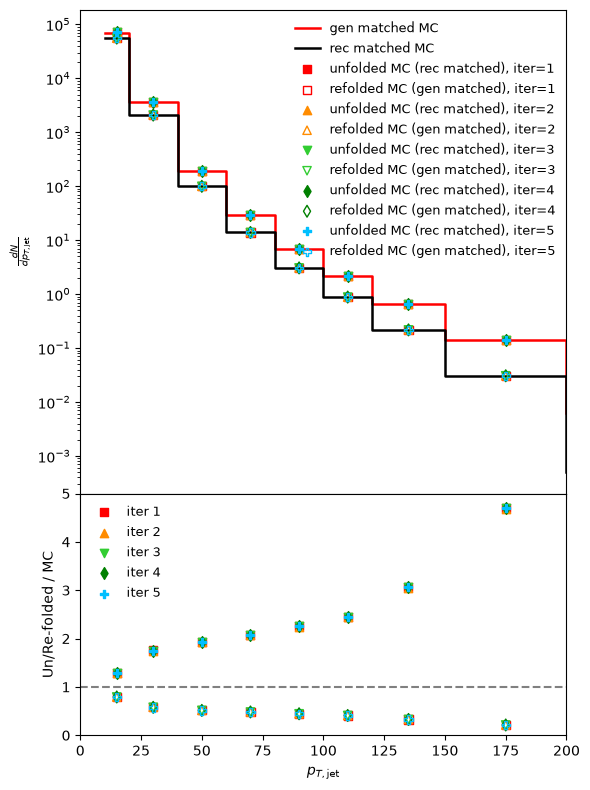

In [16]:
# COMPARISON OF UNFOLDED DISTRIBUTIONS FROM UNFOLDING FILE (-) AND REFOLDING FILE (--)

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

ax.step(binning[0][:-1], y1_gen_matched / binwidths[0], where="post", color='red', lw=1.8, ls='-',
            label="gen matched MC", zorder=3)
ax.step(binning[0][:-1], y1_reco_matched / binwidths[0], where="post", color='black', lw=1.8, ls='-',
            label="rec matched MC", zorder=3)
for i in range(n_iter):
    ax.scatter(bincenters[0], y1_trivial_unfolded_matched[i] / binwidths[0], color=L_colors[i], marker=L_markers[i],
                label="unfolded MC (rec matched), iter={}".format(i+1), zorder=3)
    ax.scatter(bincenters[0], y1_trivial_refolded_matched[i] / binwidths[0], color=L_colors[i], marker=L_markers[i], facecolors='none',
                label="refolded MC (gen matched), iter={}".format(i+1), zorder=3)

ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)


for i in range(n_iter):
    yvals_ratio = safe_divide(y1_trivial_unfolded_matched[i], y1_reco_matched, filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=L_markers[i], zorder=3, label="iter {}".format(i+1))

    yvals_ratio = safe_divide(y1_trivial_refolded_matched[i], y1_gen_matched, filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=L_markers[i], facecolors='none', zorder=3) #, label="iter {}".format(i+1))

    # if i != 0:
    #     continue
    # yvals_ratio = safe_divide(y1_trivial_unfolded_all_unefficiency[i], y1_reco_all, filler=1)
    # ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=',', alpha=0.5, zorder=3) #, label="iter {}".format(i+1)) 

    # yvals_ratio = safe_divide(y1_trivial_unfolded_all_unpurity[i], y1_reco_all, filler=1)
    # ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker='.', alpha=0.5, zorder=3) #, label="iter {}".format(i+1)) 

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
ax.set_ylim(0, 5.0)
ax.set_ylabel("Un/Re-folded / MC")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()

/tmp/ipykernel_2113144/72391723.py:41: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=',', alpha=0.5, zorder=3) #, label="iter {}".format(i+1))


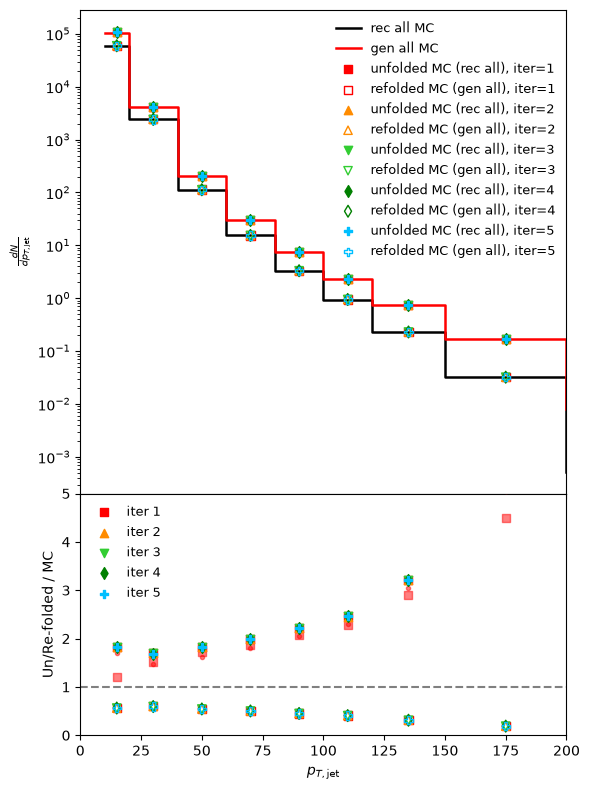

In [15]:
# COMPARISON OF UNFOLDED DISTRIBUTIONS FROM UNFOLDING FILE (-) AND REFOLDING FILE (--)

fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0]

ax.step(binning[0][:-1], y1_reco_all / binwidths[0], where="post", color='black', lw=1.8, ls='-',
            label="rec all MC", zorder=3)
ax.step(binning[0][:-1], y1_gen_all / binwidths[0], where="post", color='red', lw=1.8, ls='-',
            label="gen all MC", zorder=3)
for i in range(n_iter):
    ax.scatter(bincenters[0], y1_trivial_unfolded_all[i] / binwidths[0], color=L_colors[i], marker=L_markers[i],
                label="unfolded MC (rec all), iter={}".format(i+1), zorder=3)
    ax.scatter(bincenters[0], y1_trivial_refolded_all[i] / binwidths[0], color=L_colors[i], marker=L_markers[i], facecolors='none',
                label="refolded MC (gen all), iter={}".format(i+1), zorder=3)

ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1]
# ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)


for i in range(n_iter):
    yvals_ratio = safe_divide(y1_trivial_unfolded_all[i], y1_reco_all, filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=L_markers[i], zorder=3, label="iter {}".format(i+1))

    yvals_ratio = safe_divide(y1_trivial_refolded_all[i], y1_gen_all, filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=L_markers[i], facecolors='none', zorder=3) #, label="iter {}".format(i+1))

    if i != 0:
        continue
    yvals_ratio = safe_divide(y1_trivial_unfolded_all_unefficiency[i], y1_reco_all, filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker=',', alpha=0.5, zorder=3) #, label="iter {}".format(i+1)) 

    yvals_ratio = safe_divide(y1_trivial_unfolded_all_unpurity[i], y1_reco_all, filler=1)
    ax.scatter(bincenters[0], yvals_ratio, color=L_colors[i], marker='.', alpha=0.5, zorder=3) #, label="iter {}".format(i+1)) 

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")
ax.set_ylim(0, 5.0)
ax.set_ylabel("Un/Re-folded / MC")
ax.legend(frameon=False, fontsize=9) #, ncol=2)

fig.tight_layout()
plt.show()

# Flattening the response matrix during unfolding?

In [13]:
import numpy as np
import pandas as pd
import uproot as ur
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ---- set these ----
f_old = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded.root")  # old: 3D RooUnfoldResponse
f_new = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded_flattened_check.root")             # new: flattened 1D
f_rm  = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/response_groomed_forunfolding_merged.root")

labels    = ["AA", "AB", "BB", "rad"]
n_iter    = 5
L_colors  = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_markers = ['s', '^', 'v', 'd', 'P']

axis_names = [r"jet $p_{T}$ (GeV/$c$)", r"$R_{L}$", "energy weight"]
log_x      = [True, True, True]   # all three axes are log-binned (pT bins are irregular; log reads better)


def load(f, name):
    """Return values, variances (shape nx,ny,nz, no flow bins) and the three edge arrays."""
    h = f[name]
    return h.values(), h.variances(), [h.axis(k).edges() for k in range(3)]


def load_unf(f, lab, it):
    return load(f, f"Bayesian_Unfolded_{lab}_iter{it}")


def project(vals, var, axis):
    """1D projection onto 'axis'; errors added in quadrature (bin correlations ignored)."""
    other = tuple(k for k in range(3) if k != axis)
    return vals.sum(axis=other), np.sqrt(var.sum(axis=other))


def ratio(a, b, fill=np.nan):
    a, b = np.asarray(a, float), np.asarray(b, float)
    out = np.full_like(a, fill)
    np.divide(a, b, out=out, where=(b != 0))
    return out


def centers(edges, log=True):
    return np.sqrt(edges[:-1] * edges[1:]) if log else 0.5 * (edges[:-1] + edges[1:])

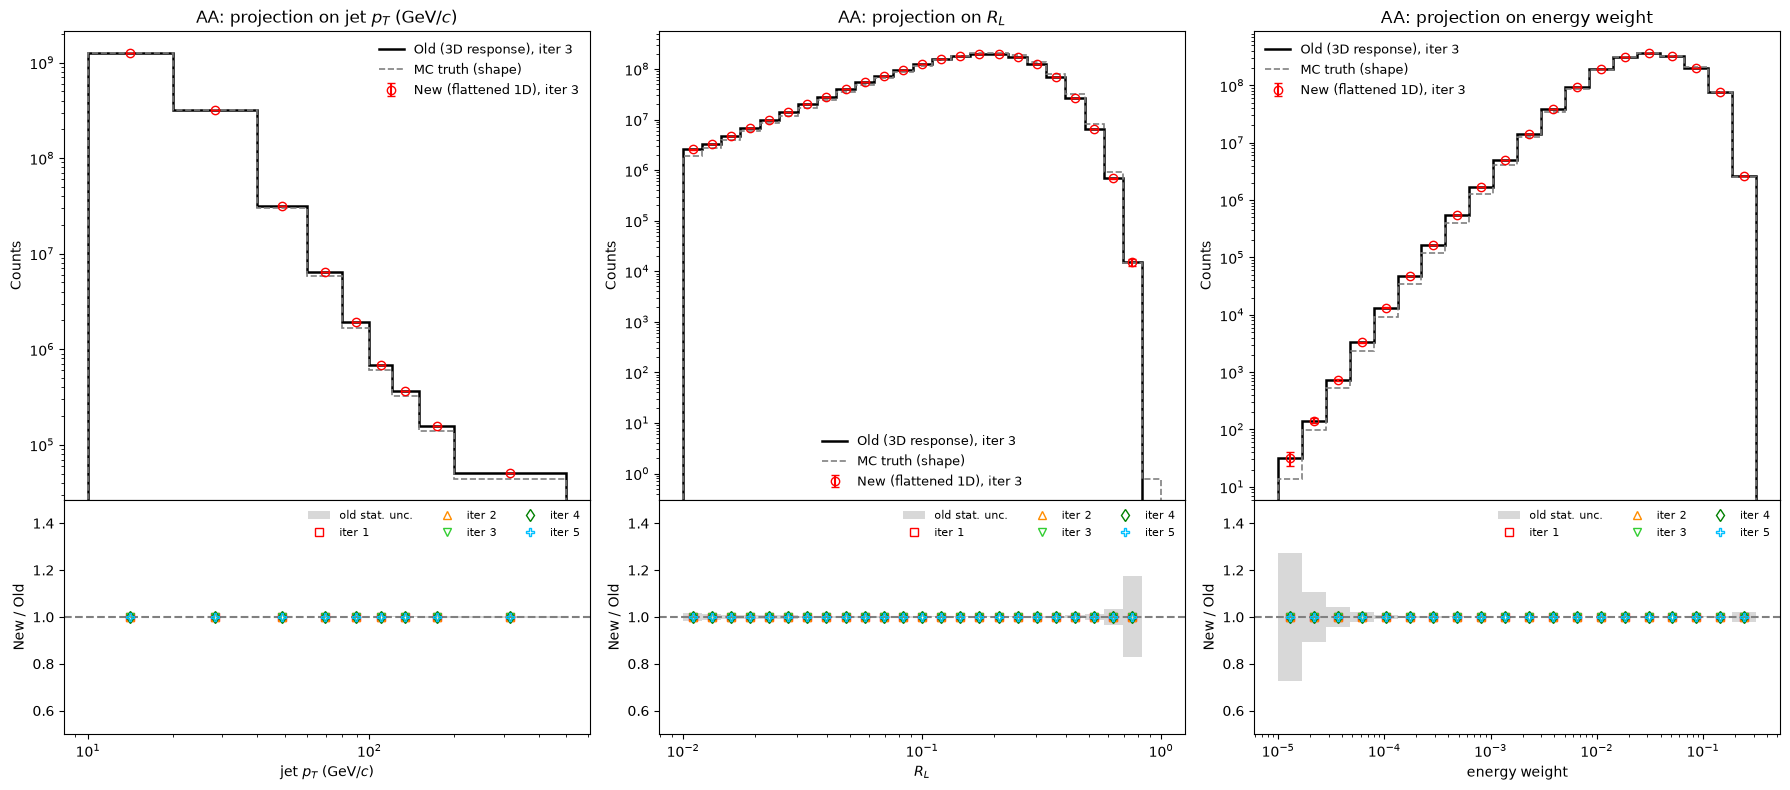

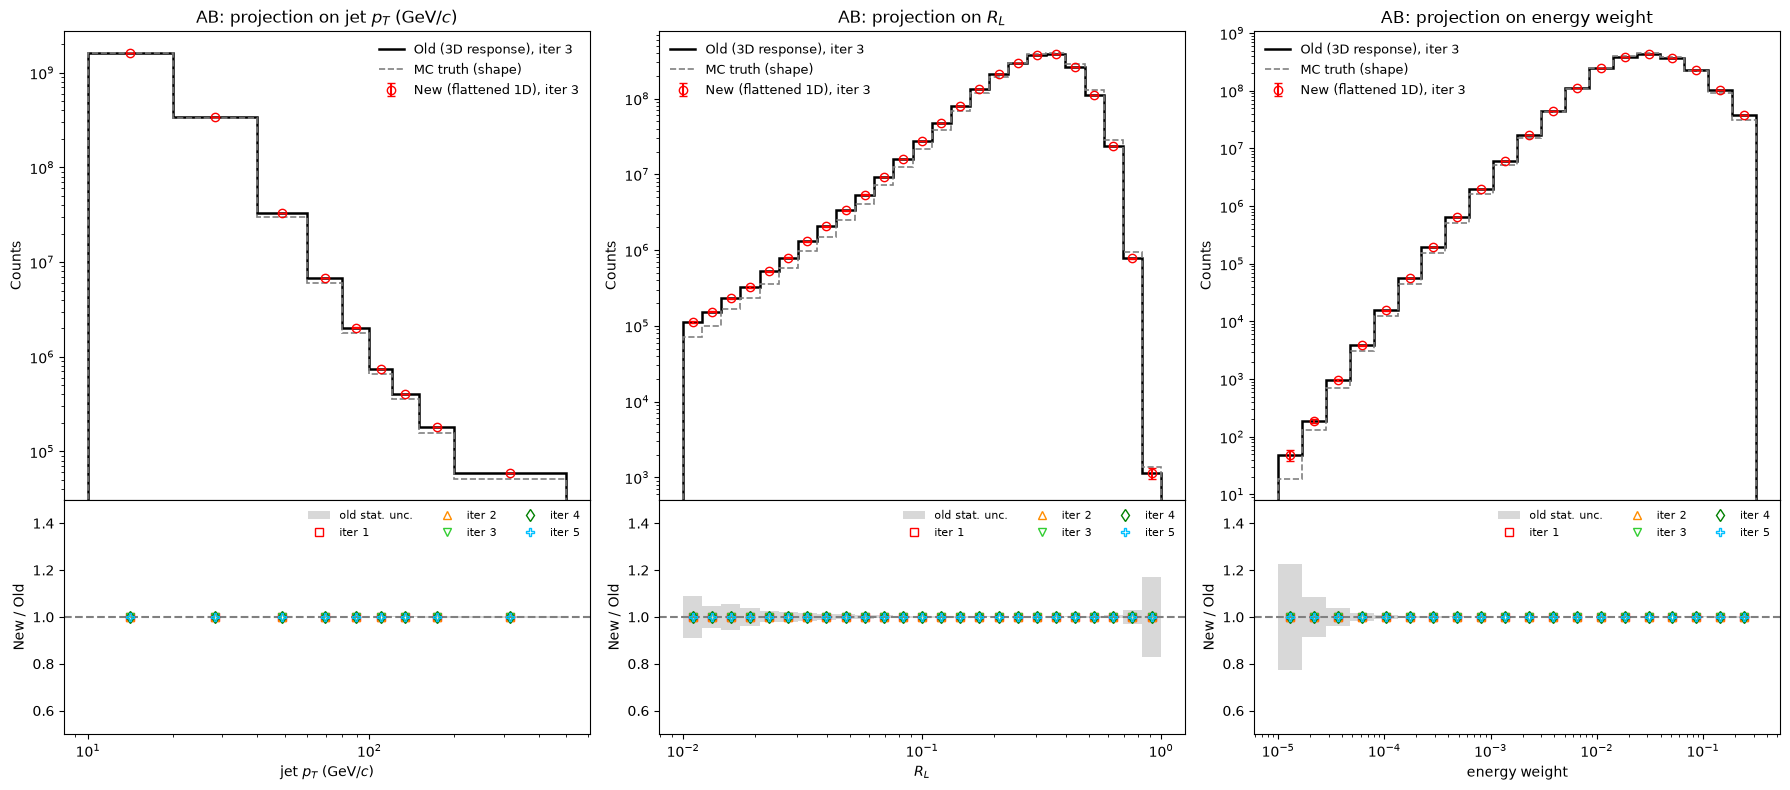

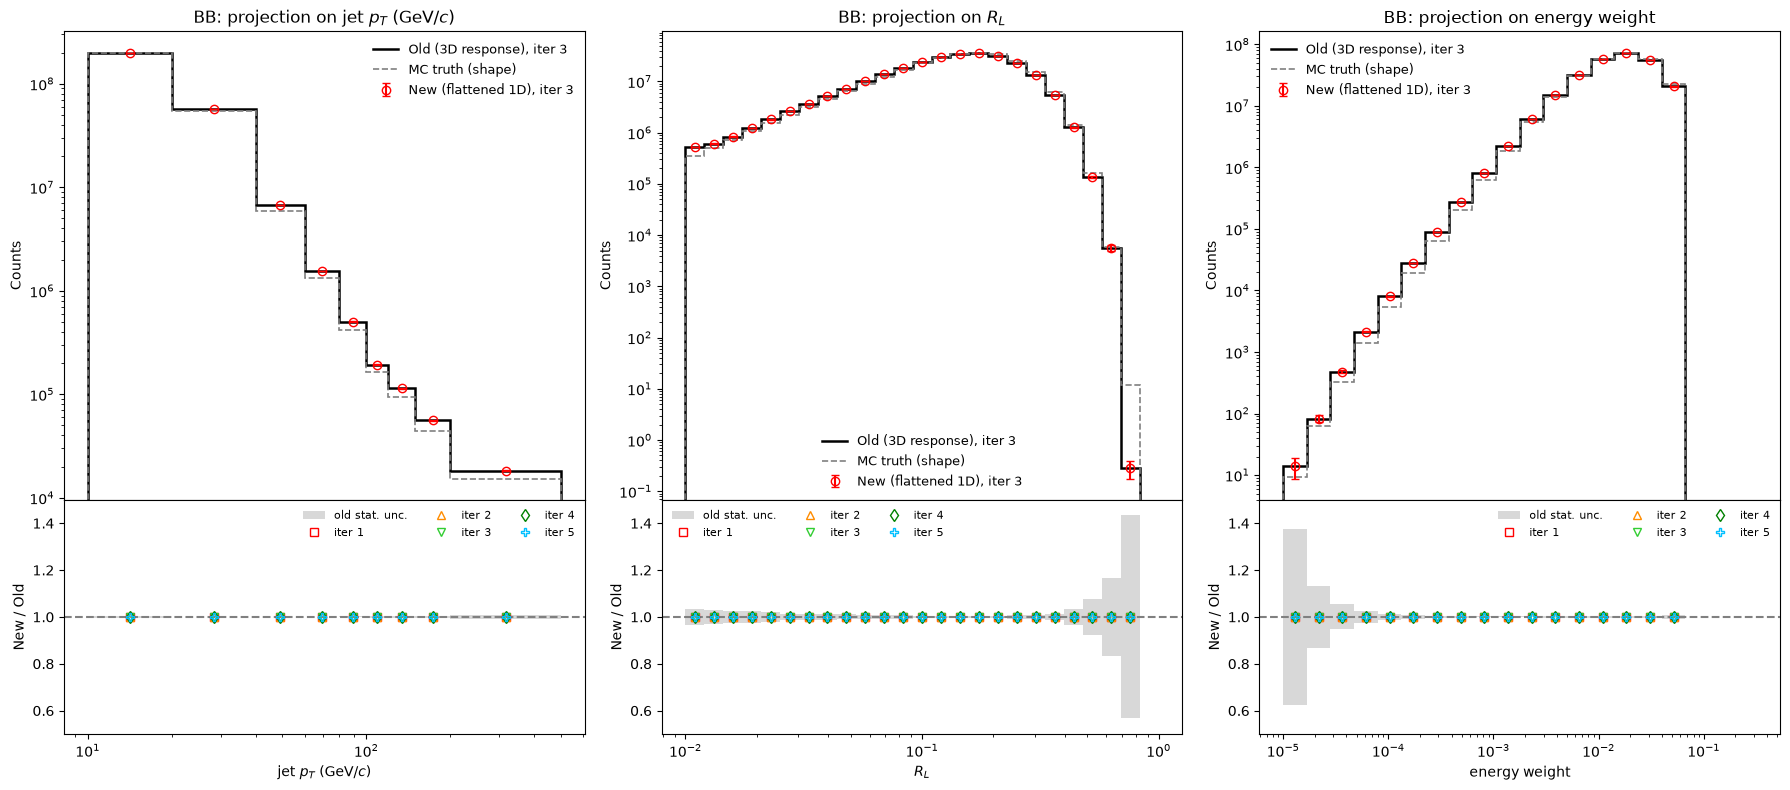

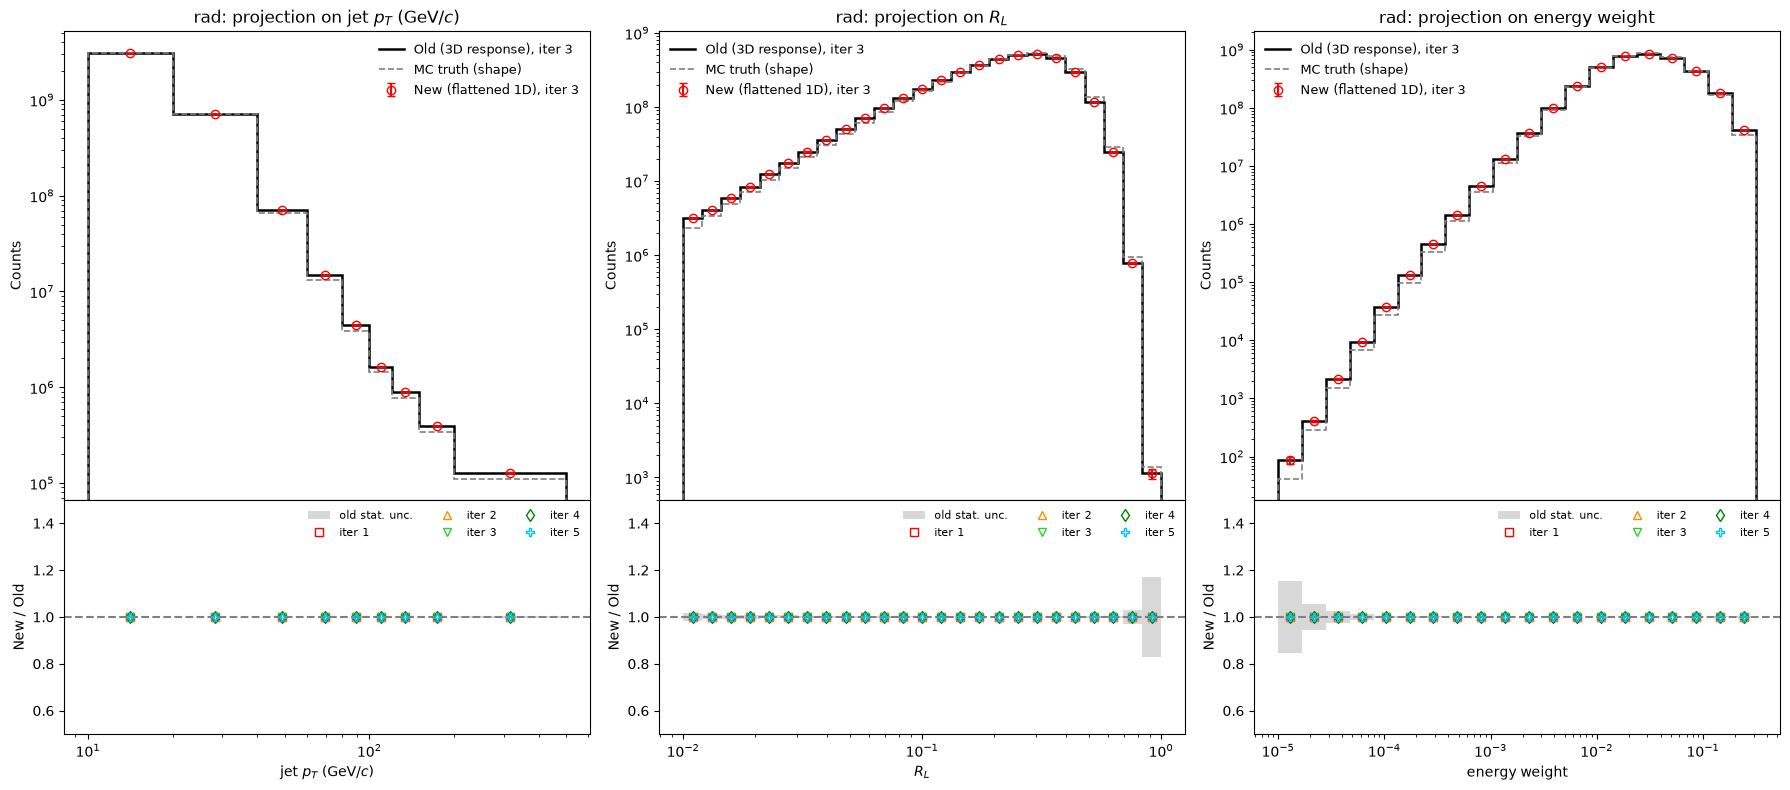

In [14]:
def compare_projections(lab, it_show=3, show_truth=True):
    v_old, e_old, edges = load_unf(f_old, lab, it_show)
    v_new, e_new, _     = load_unf(f_new, lab, it_show)
    if show_truth:
        v_tru, _, _ = load(f_rm, f"groomed_{lab}_gen_unmatched")

    fig, axs = plt.subplots(2, 3, figsize=(18, 8), sharex='col',
                            gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})

    for a in range(3):
        x = centers(edges[a], log_x[a])

        # ---- top: distributions ----
        ax = axs[0, a]
        p_old, pe_old = project(v_old, e_old, a)
        p_new, pe_new = project(v_new, e_new, a)

        ax.stairs(p_old, edges[a], color='black', lw=1.8, label=f"Old (3D response), iter {it_show}")
        ax.errorbar(x, p_new, yerr=pe_new, fmt='o', color='red', mfc='none', capsize=3,
                    linestyle='None', label=f"New (flattened 1D), iter {it_show}")
        if show_truth:
            p_tru = v_tru.sum(axis=tuple(k for k in range(3) if k != a))
            p_tru = p_tru * p_new.sum() / p_tru.sum()
            ax.stairs(p_tru, edges[a], color='gray', ls='--', lw=1.2, label="MC truth (shape)")

        if log_x[a]: ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_ylabel("Counts")
        ax.set_title(f"{lab}: projection on {axis_names[a]}")
        ax.legend(frameon=False, fontsize=9)

        # ---- bottom: new / old for all iterations ----
        ax = axs[1, a]
        rel_err_old = ratio(pe_old, p_old, fill=0)
        ax.fill_between(edges[a], np.append(1 - rel_err_old, 1 - rel_err_old[-1]),
                        np.append(1 + rel_err_old, 1 + rel_err_old[-1]),
                        step='post', color='gray', alpha=0.3, lw=0, label="old stat. unc.")
        ax.axhline(1, color='gray', ls='--')

        for it in range(1, n_iter + 1):
            vo, eo, _ = load_unf(f_old, lab, it)
            vn, en, _ = load_unf(f_new, lab, it)
            r = ratio(project(vn, en, a)[0], project(vo, eo, a)[0])
            ax.plot(x, r, marker=L_markers[(it - 1) % len(L_markers)], color=L_colors[it - 1],
                    ls='None', mfc='none', label=f"iter {it}")

        ax.set_ylim(0.5, 1.5)
        ax.set_xlabel(axis_names[a])
        ax.set_ylabel("New / Old")
        ax.legend(frameon=False, fontsize=8, ncol=3)

    fig.tight_layout()
    fig.subplots_adjust(hspace=0)
    plt.show()


for lab in labels:
    compare_projections(lab, it_show=3)

In [15]:
rows = []
for lab in labels:
    for it in range(1, n_iter + 1):
        vo, eo, _ = load_unf(f_old, lab, it)
        vn, en, _ = load_unf(f_new, lab, it)
        row = {"obj": lab, "iter": it,
               "int_old": vo.sum(), "int_new": vn.sum(), "new/old": vn.sum() / vo.sum()}
        for a, short in enumerate(["pt", "RL", "w"]):
            po, peo = project(vo, eo, a)
            pn, pen = project(vn, en, a)
            r = ratio(pn, po)
            row[f"max|dev| {short}"] = np.nanmax(np.abs(r - 1))
            sig2 = peo**2 + pen**2
            m = sig2 > 0
            row[f"chi2/ndf {short}"] = np.sum((pn[m] - po[m])**2 / sig2[m]) / m.sum()
        rows.append(row)

df_cmp = pd.DataFrame(rows)
pd.options.display.float_format = "{:.4g}".format
df_cmp

,obj,iter,int_old,int_new,new/old,max|dev| pt,chi2/ndf pt,max|dev| RL,chi2/ndf RL,max|dev| w,chi2/ndf w
0,AA,1,1.625e+09,1.625e+09,1,0,0,0,0,0,0
1,AA,2,1.626e+09,1.626e+09,1,0,0,0,0,0,0
2,AA,3,1.626e+09,1.626e+09,1,0,0,0,0,0,0
3,AA,4,1.626e+09,1.626e+09,1,0,0,0,0,0,0
4,AA,5,1.626e+09,1.626e+09,1,0,0,0,0,0,0
5,AB,1,2.002e+09,2.002e+09,1,0,0,0,0,0,0
6,AB,2,2.003e+09,2.003e+09,1,0,0,0,0,0,0
7,AB,3,2.003e+09,2.003e+09,1,0,0,0,0,0,0
8,AB,4,2.003e+09,2.003e+09,1,0,0,0,0,0,0
9,AB,5,2.003e+09,2.003e+09,1,0,0,0,0,0,0


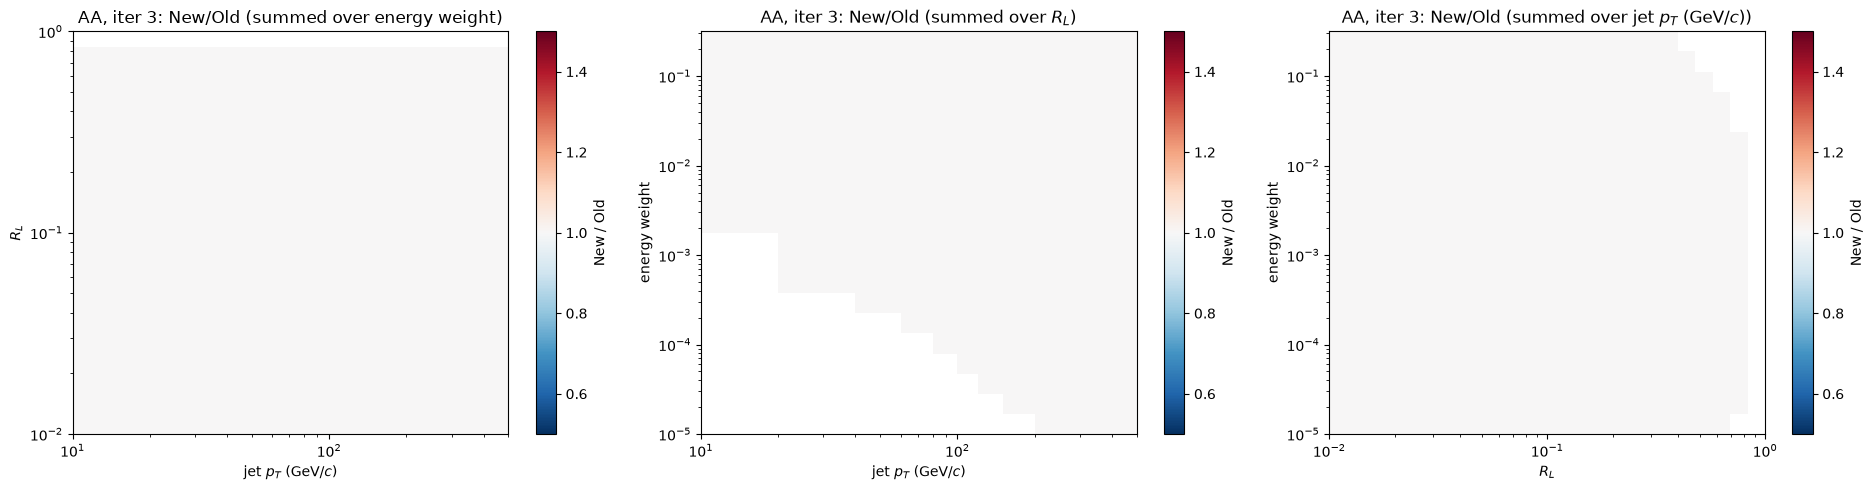

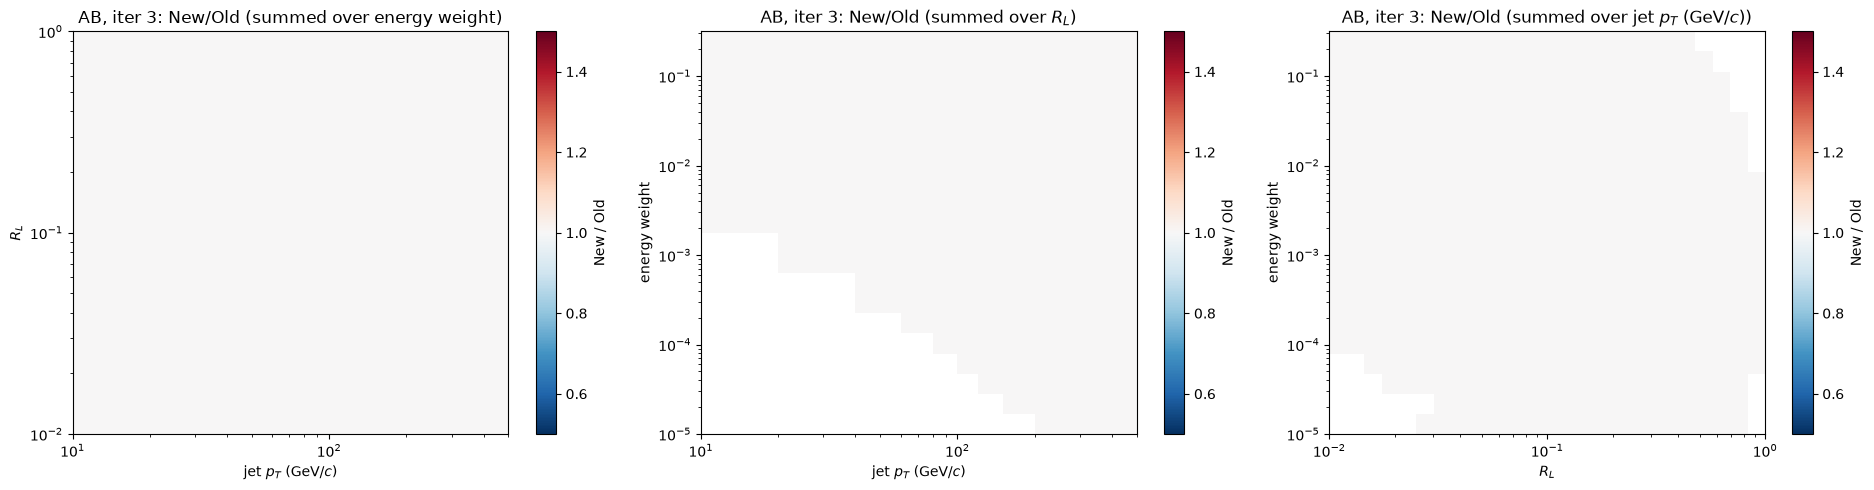

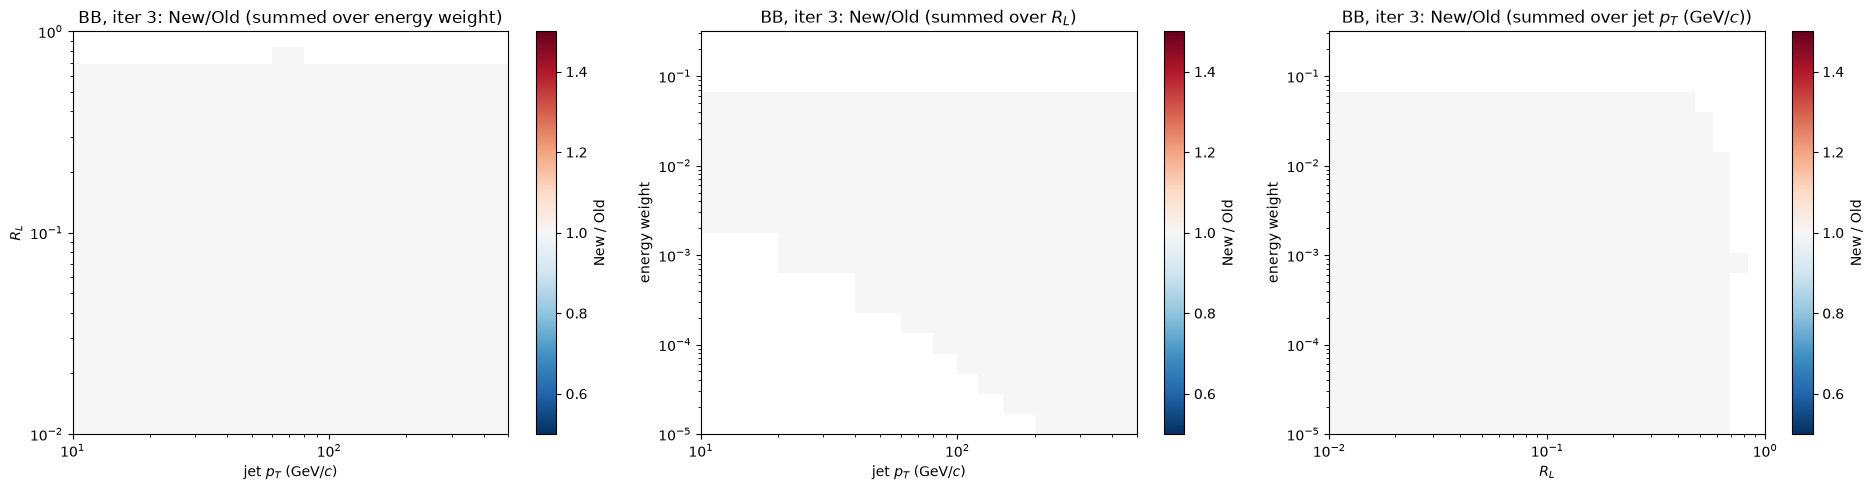

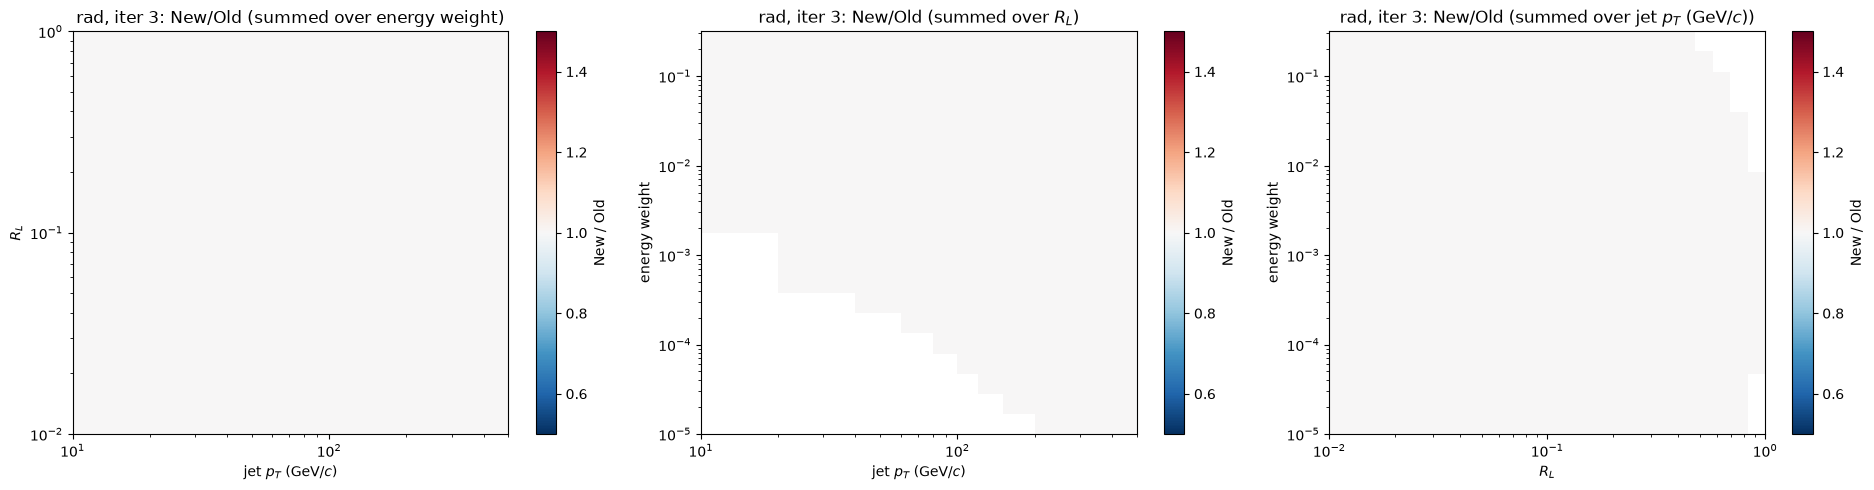

In [16]:
def ratio_maps(lab, it=3, vmin=0.5, vmax=1.5):
    vo, _, edges = load_unf(f_old, lab, it)
    vn, _, _     = load_unf(f_new, lab, it)

    pairs = [(0, 1), (0, 2), (1, 2)]   # (x-axis, y-axis); the remaining axis is summed
    fig, axs = plt.subplots(1, 3, figsize=(19, 5))
    norm = TwoSlopeNorm(vmin=vmin, vcenter=1.0, vmax=vmax)

    for ax, (ax_x, ax_y) in zip(axs, pairs):
        summed = 3 - ax_x - ax_y
        r = ratio(vn.sum(axis=summed), vo.sum(axis=summed))   # shape (n_ax_x, n_ax_y)
        pc = ax.pcolormesh(edges[ax_x], edges[ax_y], r.T, cmap='RdBu_r', norm=norm, shading='flat')
        if log_x[ax_x]: ax.set_xscale('log')
        if log_x[ax_y]: ax.set_yscale('log')
        ax.set_xlabel(axis_names[ax_x])
        ax.set_ylabel(axis_names[ax_y])
        ax.set_title(f"{lab}, iter {it}: New/Old (summed over {axis_names[summed]})")
        fig.colorbar(pc, ax=ax, label="New / Old")

    fig.tight_layout()
    plt.show()


for lab in labels:
    ratio_maps(lab, it=3)

In [17]:
def top_discrepant_bins(lab, it=3, n_show=15, min_content=0.0):
    vo, eo, edges = load_unf(f_old, lab, it)
    vn, en, _     = load_unf(f_new, lab, it)
    nx, ny, nz = vo.shape

    sig = np.sqrt(eo + en)          # eo/en are variances here
    pull = np.zeros_like(vo)
    np.divide(vn - vo, sig, out=pull, where=sig > 0)
    pull[(vo <= min_content) & (vn <= min_content)] = 0

    idx = np.argsort(np.abs(pull).ravel())[::-1][:n_show]
    out = []
    for flat in idx:
        ix, iy, iz = np.unravel_index(flat, vo.shape)
        j = ix + nx * iy + nx * ny * iz        # 0-based flat truth index (x fastest)
        out.append({"flat_bin": j, "ix": ix + 1, "iy": iy + 1, "iz": iz + 1,
                    "pT": f"[{edges[0][ix]:.0f},{edges[0][ix+1]:.0f}]",
                    "RL": f"[{edges[1][iy]:.3g},{edges[1][iy+1]:.3g}]",
                    "w":  f"[{edges[2][iz]:.2g},{edges[2][iz+1]:.2g}]",
                    "old": vo[ix, iy, iz], "new": vn[ix, iy, iz],
                    "new/old": vn[ix, iy, iz] / vo[ix, iy, iz] if vo[ix, iy, iz] != 0 else np.inf,
                    "pull": pull[ix, iy, iz]})
    return pd.DataFrame(out)


for lab in labels:
    print(f"===== {lab} =====")
    display(top_discrepant_bins(lab, it=3))

===== AA =====


,flat_bin,ix,iy,iz,pT,RL,w,old,new,new/old,pull
0,4499,9,25,20,"[200,500]","[0.832,1]","[0.19,0.32]",0,0,inf,0
1,4274,9,25,19,"[200,500]","[0.832,1]","[0.11,0.19]",0,0,inf,0
2,4049,9,25,18,"[200,500]","[0.832,1]","[0.067,0.11]",0,0,inf,0
3,3824,9,25,17,"[200,500]","[0.832,1]","[0.04,0.067]",0,0,inf,0
4,3599,9,25,16,"[200,500]","[0.832,1]","[0.024,0.04]",0,0,inf,0
5,3374,9,25,15,"[200,500]","[0.832,1]","[0.014,0.024]",0,0,inf,0
6,3149,9,25,14,"[200,500]","[0.832,1]","[0.0084,0.014]",0,0,inf,0
7,2924,9,25,13,"[200,500]","[0.832,1]","[0.005,0.0084]",0,0,inf,0
8,2699,9,25,12,"[200,500]","[0.832,1]","[0.003,0.005]",0,0,inf,0
9,2474,9,25,11,"[200,500]","[0.832,1]","[0.0018,0.003]",0,0,inf,0


===== AB =====


,flat_bin,ix,iy,iz,pT,RL,w,old,new,new/old,pull
0,4499,9,25,20,"[200,500]","[0.832,1]","[0.19,0.32]",0,0,inf,0
1,4274,9,25,19,"[200,500]","[0.832,1]","[0.11,0.19]",0,0,inf,0
2,4049,9,25,18,"[200,500]","[0.832,1]","[0.067,0.11]",0,0,inf,0
3,3824,9,25,17,"[200,500]","[0.832,1]","[0.04,0.067]",0,0,inf,0
4,3599,9,25,16,"[200,500]","[0.832,1]","[0.024,0.04]",0,0,inf,0
5,3374,9,25,15,"[200,500]","[0.832,1]","[0.014,0.024]",0,0,inf,0
6,3149,9,25,14,"[200,500]","[0.832,1]","[0.0084,0.014]",0,0,inf,0
7,2924,9,25,13,"[200,500]","[0.832,1]","[0.005,0.0084]",0,0,inf,0
8,2699,9,25,12,"[200,500]","[0.832,1]","[0.003,0.005]",0,0,inf,0
9,2474,9,25,11,"[200,500]","[0.832,1]","[0.0018,0.003]",0,0,inf,0


===== BB =====


,flat_bin,ix,iy,iz,pT,RL,w,old,new,new/old,pull
0,4499,9,25,20,"[200,500]","[0.832,1]","[0.19,0.32]",0,0,inf,0
1,4274,9,25,19,"[200,500]","[0.832,1]","[0.11,0.19]",0,0,inf,0
2,4049,9,25,18,"[200,500]","[0.832,1]","[0.067,0.11]",0,0,inf,0
3,3824,9,25,17,"[200,500]","[0.832,1]","[0.04,0.067]",0,0,inf,0
4,3599,9,25,16,"[200,500]","[0.832,1]","[0.024,0.04]",0,0,inf,0
5,3374,9,25,15,"[200,500]","[0.832,1]","[0.014,0.024]",0,0,inf,0
6,3149,9,25,14,"[200,500]","[0.832,1]","[0.0084,0.014]",0,0,inf,0
7,2924,9,25,13,"[200,500]","[0.832,1]","[0.005,0.0084]",0,0,inf,0
8,2699,9,25,12,"[200,500]","[0.832,1]","[0.003,0.005]",0,0,inf,0
9,2474,9,25,11,"[200,500]","[0.832,1]","[0.0018,0.003]",0,0,inf,0


===== rad =====


,flat_bin,ix,iy,iz,pT,RL,w,old,new,new/old,pull
0,4499,9,25,20,"[200,500]","[0.832,1]","[0.19,0.32]",0,0,inf,0
1,4274,9,25,19,"[200,500]","[0.832,1]","[0.11,0.19]",0,0,inf,0
2,4049,9,25,18,"[200,500]","[0.832,1]","[0.067,0.11]",0,0,inf,0
3,3824,9,25,17,"[200,500]","[0.832,1]","[0.04,0.067]",0,0,inf,0
4,3599,9,25,16,"[200,500]","[0.832,1]","[0.024,0.04]",0,0,inf,0
5,3374,9,25,15,"[200,500]","[0.832,1]","[0.014,0.024]",0,0,inf,0
6,3149,9,25,14,"[200,500]","[0.832,1]","[0.0084,0.014]",0,0,inf,0
7,2924,9,25,13,"[200,500]","[0.832,1]","[0.005,0.0084]",0,0,inf,0
8,2699,9,25,12,"[200,500]","[0.832,1]","[0.003,0.005]",0,0,inf,0
9,2474,9,25,11,"[200,500]","[0.832,1]","[0.0018,0.003]",0,0,inf,0


# END